## **BREAST CANCER DETECTION**

### **0 - Data loading and exploring**

In [2]:
#1. Setup and data loading
%pip install numpy
import numpy as np
import random

#Set the random seed

SEED = 7
random.seed(SEED)
np.random.seed(SEED)

#Load the dataset
data = np.load("breastmnist_128.npz", allow_pickle=False)

#Inspect the array stored in the file
print("Available arrays:", data.files)

for name in data.files:
  array = data[name]
  print(f"{name:15s} | shape : {str(array.shape):18s} | dtype: {array.dtype}")

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl (12.6 MB)
Note: you may need to restart the kernel to use updated packages.
Available arrays: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
train_images    | shape : (546, 128, 128)    | dtype: uint8
train_labels    | shape : (546, 1)           | dtype: uint8
val_images      | shape : (78, 128, 128)     | dtype: uint8
val_labels      | shape : (78, 1)            | dtype: uint8
test_images     | shape : (156, 128, 128)    | dtype: uint8
test_labels     | shape : (156, 1)           | dtype: uint8


In [4]:
#2. Information
%pip install medmnist
from medmnist import INFO

info = INFO['breastmnist']
print(info['label'])
print(info['n_samples'])  # official split sizes

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl (9.7 MB)
Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl (7.2 MB)
   ---------------------------------------- 0.0/11.9 MB ? eta 

We observe that in the dataset, the label 0 corresponds to “malignant”, while the label 1 corresponds to “normal, benign”.

Furthermore, we observe a class imbalance: approximately 73% of the images are normal/benign, while 27% are malignant. This explains why we will carefully examine the recall of the malignant class, beyond overall accuracy.

In [5]:
#3. Extract images and encode the target
x_train = data["train_images"]
x_val = data["val_images"]
x_test = data["test_images"]

#Original labels, converted to one-dimensional arrays
y_train_raw = data["train_labels"].ravel()
y_val_raw = data["val_labels"].ravel()
y_test_raw = data["test_labels"].ravel()

#Recode: 0 = normal/benign, 1 = malignant
y_train = (y_train_raw == 0).astype(int)
y_val = (y_val_raw == 0).astype(int)
y_test = (y_test_raw == 0).astype(int)

CLASS_NAMES = ["Normal / benign", "Malignant"]

# Check dimensions and class counts
for name, images, labels in [
    ("Train", x_train, y_train),
    ("Validation", x_val, y_val),
    ("Test", x_test, y_test)
]:
    print(f"{name}: X = {images.shape}, y = {labels.shape}")
    print(
        f"  Normal / benign: {(labels == 0).sum()} | "
        f"Malignant: {(labels == 1).sum()}"
    )

Train: X = (546, 128, 128), y = (546,)
  Normal / benign: 399 | Malignant: 147
Validation: X = (78, 128, 128), y = (78,)
  Normal / benign: 57 | Malignant: 21
Test: X = (156, 128, 128), y = (156,)
  Normal / benign: 114 | Malignant: 42


For consistency and clarity, we chose to invert the labels, assigning the code 1 to the “malignant” class and the code 0 to the “normal, benign” class.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 10.2 MB/s eta 0:00:00
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Note: you may need to restart the kernel to use updated packages.


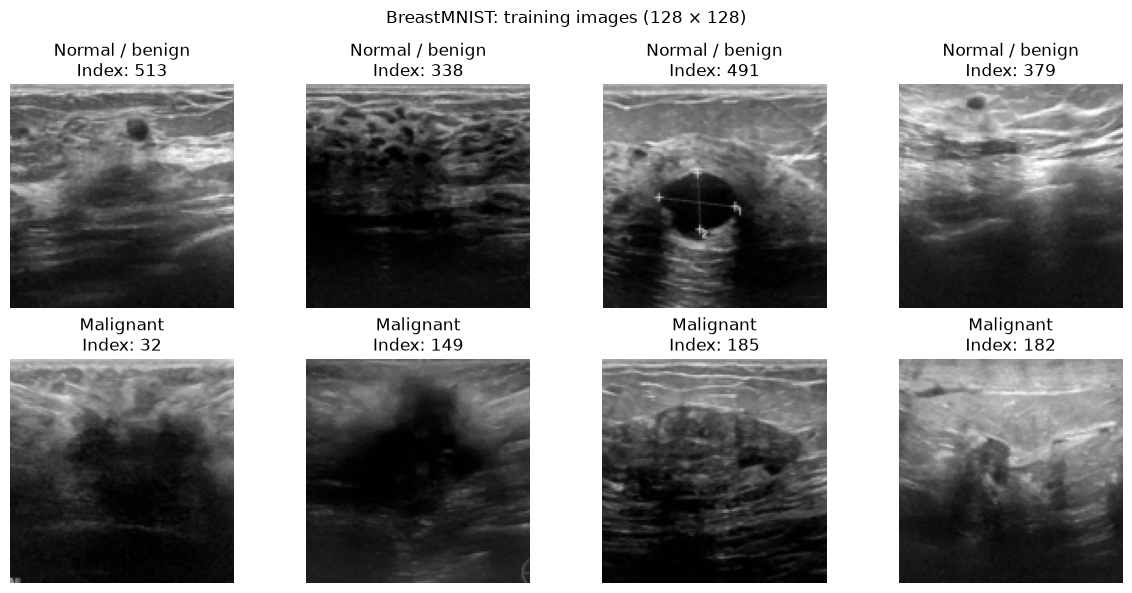

In [8]:
#4. Visualize training images from each class
%pip install matplotlib
import matplotlib.pyplot as plt

# Reproducible selection of examples
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for label in [0, 1]:
    # Find images belonging to this class
    class_indices = np.where(y_train == label)[0]

    # Select four different images
    selected_indices = rng.choice(
        class_indices, size=4, replace=False
    )

    for column, index in enumerate(selected_indices):
        ax = axes[label, column]

        ax.imshow(
            x_train[index],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        ax.set_title(f"{CLASS_NAMES[label]}\nIndex: {index}")
        ax.axis("off")

fig.suptitle("BreastMNIST: training images (128 × 128)")
plt.tight_layout()
plt.show()

We perform an initial visual inspection, examining the appearance of the ultrasound images, their contrast, the diversity of the examples, and any obvious display anomalies. We have randomly selected four normal or benign images and four malignant images from the training set, using a fixed seed to ensure this selection is reproducible.

### **I - Preprocessing**

The additional preprocessing step for this project is the median filter. However, it must be applied first, before scaling.

Train: (546, 128, 128), uint8, mean change 3.40 gray levels
Validation: (78, 128, 128), uint8, mean change 3.44 gray levels
Test: (156, 128, 128), uint8, mean change 3.45 gray levels


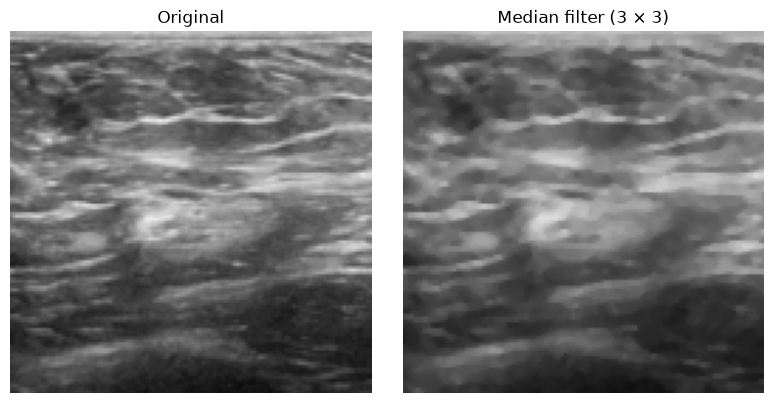

In [9]:
#5. Additional preprocessing: median filtering (3 x 3), applied to every split
from scipy.ndimage import median_filter

MEDIAN_SIZE = 3

def apply_median(images, size=MEDIAN_SIZE):
    """k x k median filter inside each image. size=(1, k, k) uses 1 along the image axis,
    so images never mix. Input and output stay uint8 (0-255)."""
    return median_filter(images, size=(1, size, size), mode="reflect")

x_train_med = apply_median(x_train)
x_val_med   = apply_median(x_val)
x_test_med  = apply_median(x_test)

for name, before, after in [("Train", x_train, x_train_med),
                            ("Validation", x_val, x_val_med),
                            ("Test", x_test, x_test_med)]:
    change = np.abs(before.astype(int) - after.astype(int)).mean()
    print(f"{name}: {after.shape}, {after.dtype}, mean change {change:.2f} gray levels")

# Compare original and filtered image on the SAME intensity scale (0-255 for uint8)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, image, title in zip(axes, [x_train[0], x_train_med[0]],
                            ["Original", f"Median filter ({MEDIAN_SIZE} × {MEDIAN_SIZE})"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
#6. We check the dimension of our images
for i, image in enumerate(x_train):
    print(f"Image {i} : {image.shape}")

Image 0 : (128, 128)
Image 1 : (128, 128)
Image 2 : (128, 128)
Image 3 : (128, 128)
Image 4 : (128, 128)
Image 5 : (128, 128)
Image 6 : (128, 128)
Image 7 : (128, 128)
Image 8 : (128, 128)
Image 9 : (128, 128)
Image 10 : (128, 128)
Image 11 : (128, 128)
Image 12 : (128, 128)
Image 13 : (128, 128)
Image 14 : (128, 128)
Image 15 : (128, 128)
Image 16 : (128, 128)
Image 17 : (128, 128)
Image 18 : (128, 128)
Image 19 : (128, 128)
Image 20 : (128, 128)
Image 21 : (128, 128)
Image 22 : (128, 128)
Image 23 : (128, 128)
Image 24 : (128, 128)
Image 25 : (128, 128)
Image 26 : (128, 128)
Image 27 : (128, 128)
Image 28 : (128, 128)
Image 29 : (128, 128)
Image 30 : (128, 128)
Image 31 : (128, 128)
Image 32 : (128, 128)
Image 33 : (128, 128)
Image 34 : (128, 128)
Image 35 : (128, 128)
Image 36 : (128, 128)
Image 37 : (128, 128)
Image 38 : (128, 128)
Image 39 : (128, 128)
Image 40 : (128, 128)
Image 41 : (128, 128)
Image 42 : (128, 128)
Image 43 : (128, 128)
Image 44 : (128, 128)
Image 45 : (128, 128

Then we skip the step of resizing since all the images are already in 128X128.

In [11]:
#6. Scaling (Convert to float32 and divide pixel intensities by 255)
x_train_scaled = x_train_med.astype("float32") / 255.0
x_val_scaled = x_val_med.astype("float32") / 255.0
x_test_scaled = x_test_med.astype("float32") / 255.0

# Check the new data type and intensity range
for name, images in [
    ("Train", x_train_scaled),
    ("Validation", x_val_scaled),
    ("Test", x_test_scaled)
]:
    print(
        f"{name}: dtype={images.dtype}, "
        f"min={images.min():.3f}, max={images.max():.3f}"
    )

Train: dtype=float32, min=0.000, max=1.000
Validation: dtype=float32, min=0.000, max=1.000
Test: dtype=float32, min=0.000, max=1.000


In [12]:
#7.Preprocessing: normalize the data set

train_mean = float(x_train_scaled.mean())
train_std = float(x_train_scaled.std())
val_mean = float(x_val_scaled.mean())
val_std = float(x_val_scaled.std())
test_mean = float(x_test_scaled.mean())
test_std = float(x_test_scaled.std())

# Small constant to prevent division by zero
EPS = 1e-8

# Apply the same transformation to all three splits
x_train_norm = (x_train_scaled - train_mean) / (train_std + EPS)
x_val_norm = (x_val_scaled - val_mean) / (val_std + EPS)
x_test_norm = (x_test_scaled - test_mean) / (test_std + EPS)

print(f"Training mean before normalization: {train_mean:.4f}")
print(f"Training std before normalization:  {train_std:.4f}")
print()

# Check statistics after normalization
for name, images in [
    ("Train", x_train_norm),
    ("Validation", x_val_norm),
    ("Test", x_test_norm)
]:
    print(
        f"{name}: mean={images.mean():.4f}, "
        f"std={images.std():.4f}"
    )

Training mean before normalization: 0.3257
Training std before normalization:  0.2130

Train: mean=0.0000, std=1.0000
Validation: mean=-0.0000, std=1.0000
Test: mean=-0.0000, std=1.0000


The training set has a mean close to zero and a standard deviation close to one. The value -0.0000 corresponds to a very small negative value due to numerical precision, displayed after rounding.

For the validation and test sets, the results are slightly different because their original intensity values do not have exactly the same distribution as those of the training set.

Original images: (546, 128, 128)
Augmented images: (2730, 128, 128)
Augmented labels: (2730,)
Normal / benign: 1995
Malignant: 735


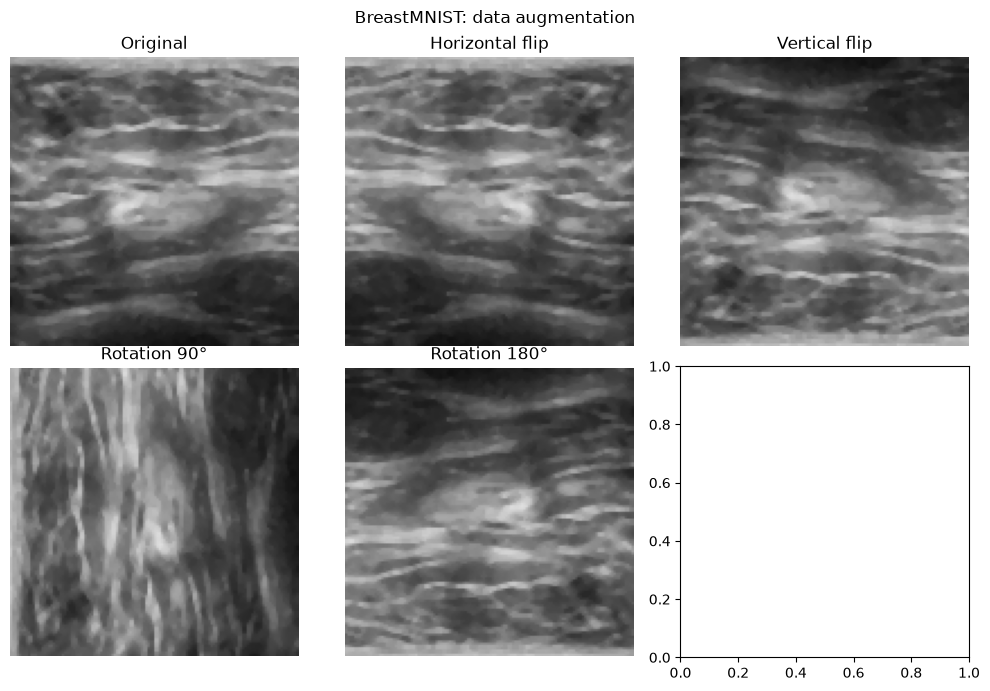

In [13]:
#8. Original training images
x_train_original = x_train_scaled

# Horizontal flip: left-right
x_train_hflip = np.flip(x_train_original, axis=2)

# Vertical flip: top-bottom
x_train_vflip = np.flip(x_train_original, axis=1)

# Rotations: 90° and 180°
x_train_rot90 = np.rot90(
    x_train_original, k=1, axes=(1, 2)
)

x_train_rot180 = np.rot90(
    x_train_original, k=2, axes=(1, 2)
)

# Combine original images and all augmented versions
x_train_aug_scaled = np.concatenate(
    [
        x_train_original,
        x_train_hflip,
        x_train_vflip,
        x_train_rot90,
        x_train_rot180
    ],
    axis=0
)

# Each transformed image keeps its original label
y_train_aug = np.concatenate(
    [y_train] * 5,
    axis=0
)

# Normalize using the original training statistics
x_train_aug_norm = (
    (x_train_aug_scaled - train_mean)
    / (train_std + EPS)
)

# Check the augmented dataset
print("Original images:", x_train_original.shape)
print("Augmented images:", x_train_aug_norm.shape)
print("Augmented labels:", y_train_aug.shape)

print("Normal / benign:", (y_train_aug == 0).sum())
print("Malignant:", (y_train_aug == 1).sum())

# Visualize all transformations of one image
index = 0

images_to_show = [
    x_train_original[index],
    x_train_hflip[index],
    x_train_vflip[index],
    x_train_rot90[index],
    x_train_rot180[index]
]

titles = [
    "Original",
    "Horizontal flip",
    "Vertical flip",
    "Rotation 90°",
    "Rotation 180°"
]

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, image, title in zip(
    axes.flat, images_to_show, titles
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("BreastMNIST: data augmentation")
plt.tight_layout()
plt.show()


This data augmentation does not correct the class imbalance, since we double the number of samples in both classes. The proportion of malignant images remains approximately 27%. The purpose of data augmentation is to provide the model with more variations during training. We keep the validation and test sets in their original form to evaluate the model's performance on the provided images, without adding transformed copies to the evaluation sets.

To address the request for additional preprocessing, we proposed a 3 × 3 median filter. It replaces each pixel with the median intensity of its neighborhood, which can reduce certain local noise variations.

We applied it to a training image and compared the result with the original using the same display scale. However, the filter may also remove details that are useful for detection. We therefore present it as an approach to be evaluated.

In [14]:
# 9. Checking all possible fliter median
import pandas as pd
from scipy.ndimage import median_filter
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score

# Re-create scaled images if they are not in memory
x_train_scaled = x_train.astype("float32")
x_val_scaled = x_val.astype("float32")

# Train + val together (624 images, 168 cancers); test stays closed. Cancer = 1.
X_all = np.concatenate([x_train_scaled, x_val_scaled]).astype("float32")
y_all = np.concatenate([y_train, y_val])

def apply_median(imgs, size):
    """size=None -> no filter. Otherwise a size x size median filter, same as your colleague's."""
    if size is None:
        return imgs
    return np.array([median_filter(im, size=size, mode="reflect") for im in imgs])

variants = {"no filter": None, "median 3x3": 3, "median 5x5": 5, "median 7x7": 7}

# 5 folds x 3 repeats = 15 splits, reused for every variant so the comparison is paired
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X_all, y_all))

scores = {}
for name, size in variants.items():
    Xv = apply_median(X_all, size).reshape(len(X_all), -1)     # filter once per image
    aucs, recs = [], []
    for tr, te in splits:
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42))
        clf.fit(Xv[tr], y_all[tr])
        p = clf.predict_proba(Xv[te])[:, 1]
        aucs.append(roc_auc_score(y_all[te], p))
        recs.append(recall_score(y_all[te], (p >= 0.5).astype(int)))
    scores[name] = (np.array(aucs), np.array(recs))

rows = []
base_auc, base_rec = scores["no filter"]
for name, (a, r) in scores.items():
    d = a - base_auc                                            # paired AUC difference per split
    rows.append({"variant": name,
                 "AUC": f"{a.mean():.3f} ± {a.std():.3f}",
                 "cancer recall": f"{r.mean():.3f} ± {r.std():.3f}",
                 "AUC diff vs no filter": f"{d.mean():+.4f}",
                 "approx. SE": f"{d.std(ddof=1) / np.sqrt(len(d)):.4f}" if name != "no filter" else "-",
                 "splits where better": f"{(d > 0).sum()}/{len(d)}" if name != "no filter" else "-"})
print(pd.DataFrame(rows).to_string(index=False))

   variant           AUC cancer recall AUC diff vs no filter approx. SE splits where better
 no filter 0.808 ± 0.038 0.619 ± 0.066               +0.0000          -                   -
median 3x3 0.809 ± 0.037 0.625 ± 0.067               +0.0009     0.0015                8/15
median 5x5 0.796 ± 0.040 0.597 ± 0.057               -0.0123     0.0028                2/15
median 7x7 0.784 ± 0.038 0.601 ± 0.058               -0.0243     0.0042                1/15


In [16]:
# 10. Checking all possible preprocessing step
%pip install opencv-python
import cv2
from PIL import Image, ImageEnhance
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


def apply_grayscaling(images):
    """Converts 3-channel RGB to 1-channel Grayscale by averaging across channels."""
    processed = []
    for img in images:
        if img.ndim == 3 and img.shape[-1] == 3:
            gray_img = img.mean(axis=-1)
        else:
            gray_img = np.squeeze(img)
        processed.append(gray_img.astype('float32'))
    return np.array(processed)

def apply_speckle_reduction(images):
    """Applies Bilateral Filtering to smooth speckle noise while preserving edges."""
    processed = []
    for img in images:
        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        img_2d = np.squeeze(img_uint8)
        if img_2d.ndim == 3 and img_2d.shape[-1] == 3:
            img_2d = cv2.cvtColor(img_2d, cv2.COLOR_RGB2GRAY)
        filtered = cv2.bilateralFilter(img_2d, d=5, sigmaColor=75, sigmaSpace=75)
        processed.append(filtered.astype('float32') / 255.0)
    return np.array(processed)

def apply_clahe(images):
    """Enhances local contrast using CLAHE."""
    processed = []
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    for img in images:
        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        img_2d = np.squeeze(img_uint8)
        if img_2d.ndim == 3 and img_2d.shape[-1] == 3:
            img_2d = cv2.cvtColor(img_2d, cv2.COLOR_RGB2GRAY)
        enhanced = clahe.apply(img_2d)
        processed.append(enhanced.astype('float32') / 255.0)
    return np.array(processed)

def apply_tophat(images):
    """Applies Top-Hat morphological filtering to isolate structural shapes/calcifications."""
    processed = []
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    for img in images:
        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        img_2d = np.squeeze(img_uint8)
        if img_2d.ndim == 3 and img_2d.shape[-1] == 3:
            img_2d = cv2.cvtColor(img_2d, cv2.COLOR_RGB2GRAY)
        tophat = cv2.morphologyEx(img_2d, cv2.MORPH_TOPHAT, kernel)
        processed.append(tophat.astype('float32') / 255.0)
    return np.array(processed)

def apply_brightness_enhancement(images, factor=1.2):
    """Applies brightness enhancement via PIL."""
    processed = []
    for img in images:
        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        img_sq = np.squeeze(img_uint8)
        pil_img = Image.fromarray(img_sq)
        enhancer = ImageEnhance.Brightness(pil_img)
        enhanced_img = enhancer.enhance(factor)
        processed.append(np.array(enhanced_img).astype('float32') / 255.0)
    return np.array(processed)

def augment_training_set(X_tr, y_tr):
    """Applies horizontal flip and rotation (+15 degrees) to training images only."""
    X_augmented, y_augmented = [], []
    for img, label in zip(X_tr, y_tr):
        # 1. Original
        X_augmented.append(img)
        y_augmented.append(label)

        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        img_sq = np.squeeze(img_uint8)
        pil_img = Image.fromarray(img_sq)

        # 2. Horizontal Flip
        flip_img = pil_img.transpose(Image.FLIP_LEFT_RIGHT)
        X_augmented.append(np.array(flip_img).astype('float32') / 255.0)
        y_augmented.append(label)

        # 3. Rotation (+15°)
        rot_img = pil_img.rotate(15, resample=Image.BILINEAR)
        X_augmented.append(np.array(rot_img).astype('float32') / 255.0)
        y_augmented.append(label)

    return np.array(X_augmented), np.array(y_augmented)


def evaluate_model(name, X_tr, X_te, y_tr, y_te):
    X_tr_flat = X_tr.reshape(X_tr.shape[0], -1)
    X_te_flat = X_te.reshape(X_te.shape[0], -1)

    clf = LogisticRegression(max_iter=10000, random_state=42)
    clf.fit(X_tr_flat, y_tr.ravel())

    preds = clf.predict(X_te_flat)
    probs = clf.predict_proba(X_te_flat)[:, 1]

    auc = roc_auc_score(y_te, probs)
    print(f"=== {name} ===")
    print(f"Recall(y=0):    {recall_score(y_te, preds, pos_label=0):.4f}")
    print(f"Recall(y=1):    {recall_score(y_te, preds, pos_label=1):.4f}")
    print(f"ROC-AUC:        {auc:.4f}\n")
    return {"Name": name, "ROC-AUC": auc}


# Assuming X, y are already loaded in your environment


print("Running individual preprocessing comparisons...\n")

# 1. Baseline
evaluate_model("1. Baseline (Raw Inputs)", x_train_scaled, x_test_scaled, y_train, y_test)

# 2. Grayscale Only
evaluate_model("2. Grayscale Only", apply_grayscaling(x_train_scaled), apply_grayscaling(x_test_scaled), y_train, y_test)

# 3. Speckle Reduction Only (Bilateral)
evaluate_model("3. Speckle Reduction Only", apply_speckle_reduction(x_train_scaled), apply_speckle_reduction(x_test_scaled), y_train, y_test)

# 4. CLAHE Only
evaluate_model("4. Contrast Enhancement (CLAHE)", apply_clahe(x_train_scaled), apply_clahe(x_test_scaled), y_train, y_test)

# 5. Top-Hat Filter Only
evaluate_model("5. Edge/Top-Hat Filter Only", apply_tophat(x_train_scaled), apply_tophat(x_test_scaled), y_train, y_test)

# 6. Brightness Enhancement Only
evaluate_model("6. Brightness Enhancement (1.2x)", apply_brightness_enhancement(x_train_scaled), apply_brightness_enhancement(x_test_scaled), y_train, y_test)

# 7. Training Set Augmentation (Flip + Rotate)
X_tr_aug, y_tr_aug = augment_training_set(x_train_scaled, y_train)
evaluate_model("7. Augmentation Only (Flip + Rotate)", X_tr_aug, x_test_scaled, y_tr_aug, y_test)


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.6/44.0 MB 9.3 MB/s eta 0:00:05
   --- ------------------------------------ 3.7/44.0 MB 9.9 MB/s eta 0:00:05
   ----- ---------------------------------- 6.3/44.0 MB 10.4 MB/s eta 0:00:04
   ------- -------------------------------- 8.7/44.0 MB 10.7 MB/s eta 0:00:04
   ---------- ----------------------------- 11.0/44.0 MB 10.7 MB/s eta 0:00:04
   ----------- ---------------------------- 13.1/44.0 MB 10.8 MB/s eta 0:00:03
   -------------- ------------------------- 15.5/44.0 MB 10.9 MB/s eta 0:00:03
   ---------------- ----------------------- 18.1/44.0 MB 11.1 MB/s eta 0:00:03
   ------------------ --------------------- 20.4/44.0 MB 11.2 MB/s eta 0:00:03
   -------------------- ------------------- 23.1/44.0 MB 11.3 MB/s eta 0:00:02
   ----------------------- ---------------- 25.7/44.0 MB 11.3 MB/s eta 0:00:02
   ------------------------- -------------- 27.8/44.0 MB 11.4 MB/s 

{'Name': '7. Augmentation Only (Flip + Rotate)', 'ROC-AUC': 0.7700501253132832}

### **II - Feature engineering**

#### II-1- First handcraft method : HOG

HOG feature vector shape: (8100,)


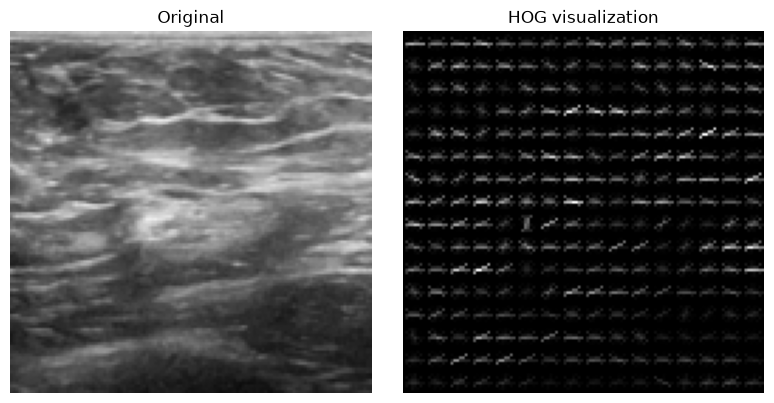

In [51]:
# 11. Feature extraction: visualize HOG on one training image
from skimage.feature import hog

index = 0

# Compute HOG from the normalized image
hog_vector, hog_image = hog(
    x_train_norm[index],
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    transform_sqrt=False,
    visualize=True,
    feature_vector=True
)

print("HOG feature vector shape:", hog_vector.shape)

# Display the original image and the HOG visualization
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(
    x_train[index], cmap="gray", vmin=0, vmax=255
)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG visualization")
axes[1].axis("off")

plt.tight_layout()
plt.show()

After preprocessing, we began extracting features to represent the images. Our first descriptor is HOG (Histogram of Oriented Gradients), which summarizes the directions and magnitudes of intensity variations across different regions of an image.

We used cells of 8 × 8 pixels, nine orientation bins, and blocks of 2 × 2 cells for local normalization. With these parameters, each 128 × 128-pixel image is represented by 8,100 features.

We first applied the method to a single image and displayed its visualization to understand the structures captured by the descriptor before extending feature extraction to the entire dataset.

In [22]:
# Extract HOG features for all three datasets
def extract_hog_features(images):
    features = [
        hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            transform_sqrt=False,
            visualize=False,
            feature_vector=True
        )
        for image in images
    ]

    return np.asarray(features, dtype=np.float32)


x_train_hog = extract_hog_features(x_train_aug_norm)
x_val_hog = extract_hog_features(x_val_norm)
x_test_hog = extract_hog_features(x_test_norm)

for name, features in [
    ("Train", x_train_hog),
    ("Validation", x_val_hog),
    ("Test", x_test_hog)
]:
    print(f"{name}: {features.shape}")

Train: (2730, 8100)
Validation: (78, 8100)
Test: (156, 8100)


After verifying that HOG worked correctly on a single image, we created a function to apply the same feature extraction process to all images.

We used the same parameters for the augmented training set, validation set, and test set. Each image is now represented by a vector of 8,100 features, resulting in three matrices that can be directly used by our classification models.

At this stage, we have only constructed the explanatory variables; no classifier has been trained yet.

#### II-2- Second handcraft method : LBP

c:\Users\kodja\AppData\Local\Programs\Python\Python312\Lib\site-packages\skimage\feature\texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


LBP feature vector shape: (10,)
Sum of proportions: 1.0000


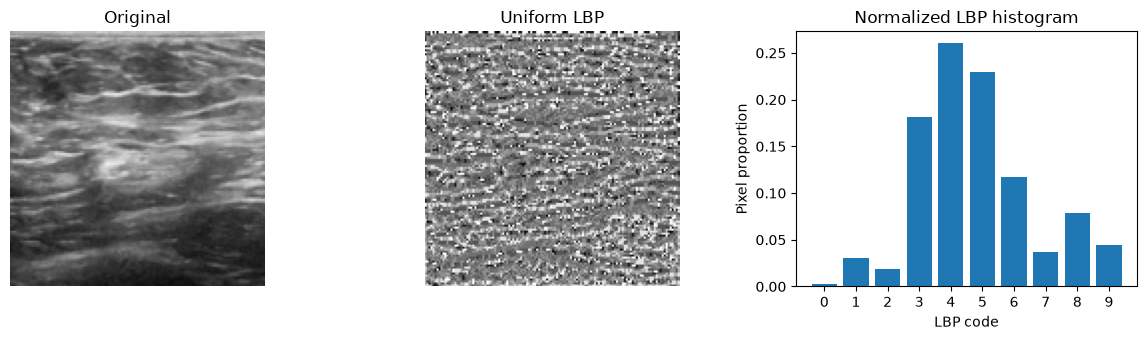

In [23]:
#12. Feature extraction: visualize LBP on one training image
from skimage.feature import local_binary_pattern

LBP_RADIUS = 1
LBP_POINTS = 8
LBP_BINS = LBP_POINTS + 2

index = 0

# Use the original integer image for LBP
lbp_image = local_binary_pattern(
    x_train_aug_norm[index],
    P=LBP_POINTS,
    R=LBP_RADIUS,
    method="uniform"
)

# Count each pattern and convert counts into proportions
lbp_vector, _ = np.histogram(
    lbp_image.ravel(),
    bins=np.arange(LBP_BINS + 1)
)
lbp_vector = lbp_vector.astype(np.float32)
lbp_vector /= lbp_vector.sum()

print("LBP feature vector shape:", lbp_vector.shape)
print(f"Sum of proportions: {lbp_vector.sum():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].imshow(x_train[index], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(lbp_image, cmap="gray", vmin=0, vmax=LBP_BINS - 1)
axes[1].set_title("Uniform LBP")
axes[1].axis("off")

axes[2].bar(np.arange(LBP_BINS), lbp_vector)
axes[2].set_title("Normalized LBP histogram")
axes[2].set_xlabel("LBP code")
axes[2].set_ylabel("Pixel proportion")
axes[2].set_xticks(np.arange(LBP_BINS))

plt.tight_layout()
plt.show()

To complement HOG, we selected a second descriptor, LBP (Local Binary Patterns), which describes image textures. It compares each pixel with its eight neighbors and converts these comparisons into binary patterns.

Using the uniform method, we group these patterns into ten categories and then calculate their proportions in the image. Each ultrasound image is therefore represented by ten texture features.

We first displayed the original image, its LBP map, and its histogram to understand this representation before applying it to all images.

In [24]:
# Extract LBP features for all three datasets
def extract_lbp_features(images):
    features = []

    for image in images:
        lbp = local_binary_pattern(
            image,
            P=LBP_POINTS,
            R=LBP_RADIUS,
            method="uniform"
        )

        histogram, _ = np.histogram(
            lbp.ravel(),
            bins=np.arange(LBP_BINS + 1)
        )

        histogram = histogram.astype(np.float32)
        histogram /= histogram.sum()
        features.append(histogram)

    return np.asarray(features, dtype=np.float32)


x_train_lbp = extract_lbp_features(x_train_aug_norm)
x_val_lbp = extract_lbp_features(x_val_norm)
x_test_lbp = extract_lbp_features(x_test_norm)

for name, features in [
    ("Train", x_train_lbp),
    ("Validation", x_val_lbp),
    ("Test", x_test_lbp)
]:
    print(f"{name}: {features.shape}")

Train: (2730, 10)
Validation: (78, 10)
Test: (156, 10)


After studying LBP on a single image, we created a function to extract this descriptor from all datasets. For each image, it computes the local patterns, counts their occurrences, and converts these counts into a histogram of ten proportions.

We used the integer pixel values and preserved exactly the same image order as for HOG, including the mirrored versions in the training set. We now have two aligned representations of each image, which we can use separately or combine.

In [25]:
# 12. Combine HOG and LBP features
x_train_combined = np.concatenate(
    [x_train_hog, x_train_lbp], axis=1
)

x_val_combined = np.concatenate(
    [x_val_hog, x_val_lbp], axis=1
)

x_test_combined = np.concatenate(
    [x_test_hog, x_test_lbp], axis=1
)

for name, features in [
    ("Train", x_train_combined),
    ("Validation", x_val_combined),
    ("Test", x_test_combined)
]:
    print(f"{name}: {features.shape}")

Train: (2730, 8110)
Validation: (78, 8110)
Test: (156, 8110)


After extracting HOG and LBP separately, we combined their features for each image. We concatenated the 8,100 HOG values with the 10 LBP proportions, resulting in a vector of 8,110 features.

The goal is to allow the models to exploit both contour and texture information simultaneously. We preserved the same image order and feature structure across all three datasets. We can then compare this combination with each descriptor used individually.

In [26]:
#13. Test over the handcraft methods and combiantions
import itertools
from skimage.feature import canny, corner_harris, corner_peaks
from sklearn.svm import LinearSVC

# Train + validation, ORIGINAL images only (the test set stays closed)
x_all_u8   = np.concatenate([x_train, x_val])            # integers 0-255, from step 2   -> used for LBP
x_all_norm = np.concatenate([x_train_norm, x_val_norm])  # scaled + normalized, step 5   -> HOG, Canny, Harris
y_all      = np.concatenate([y_train, y_val])            # malignant = 1, from step 2
n_tr = len(y_train)
assert len(x_all_u8) == len(x_all_norm) == len(y_all) == 624 and y_all.sum() == 168

# Canny and Harris are defined here (run on the normalized images)
def f_canny(imgs):      # flattened binary edge map, sigma = 1.5
    return np.array([canny(i, sigma=1.5).astype(np.float32).ravel() for i in imgs])

def f_harris(imgs):     # corner count + mean and std of the Harris response map
    out = []
    for i in imgs:
        resp = corner_harris(i, method="k", k=0.05)
        out.append([len(corner_peaks(resp, min_distance=4, threshold_rel=0.02)), resp.mean(), resp.std()])
    return np.array(out, dtype=np.float32)

def f_sift(imgs):
    # Initialize SIFT detector
    sift = cv2.SIFT_create()
    out = []
    for img in imgs:
        # Ensure image is uint8 [0, 255] for OpenCV SIFT
        img_u8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        
        # Detect keypoints and compute descriptors
        keypoints, descriptors = sift.detectAndCompute(img_u8, None)
        
        if descriptors is not None:
            # SIFT descriptors shape is (n_keypoints, 128)
            # Pool across keypoints using mean and std to get a fixed length (256,) vector
            feat = np.hstack([descriptors.mean(axis=0), descriptors.std(axis=0)])
        else:
            # Fallback for edge-case images where no SIFT features are found
            feat = np.zeros(256, dtype=np.float32)
            
        out.append(feat)
    return np.array(out, dtype=np.float32)

# Descriptors: Now including SIFT alongside HOG, LBP, Canny, and Harris
base = {
    "HOG":    extract_hog_features(x_all_norm),
    "LBP":    extract_lbp_features(x_all_u8),
    "Canny":  f_canny(x_all_norm),
    "Harris": f_harris(x_all_norm),
    "SIFT":   f_sift(x_all_norm)  
}
# 4) 4 single descriptors + all 6 pairs (never more than two descriptors)
sets = dict(base)
for a, b in itertools.combinations(base, 2):
    sets[f"{a} + {b}"] = np.hstack([base[a], base[b]])

# His two models with his settings (named cv_models so his models dict is not overwritten)
cv_models = {
    "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(
        C=1.0, solver="liblinear", class_weight="balanced", max_iter=5000, random_state=SEED)),
    "Linear SVM": lambda: make_pipeline(StandardScaler(), LinearSVC(
        C=1.0, dual="auto", class_weight="balanced", max_iter=10000, random_state=SEED)),
}

# Same 15 paired splits (5 folds x 3 repeats) for every candidate
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(x_all_u8, y_all))

def cv_scores(X, make_model):
    aucs, recs = [], []
    for tr, te in splits:
        m = make_model().fit(X[tr], y_all[tr])
        aucs.append(roc_auc_score(y_all[te], m.decision_function(X[te])))
        recs.append(recall_score(y_all[te], m.predict(X[te])))     # malignant recall
    return np.array(aucs), np.array(recs)

REF = "HOG + LBP"
for model_name, make_model in cv_models.items():
    res = {name: cv_scores(X, make_model) for name, X in sets.items()}
    ref_auc = res[REF][0]
    rows = []
    for name, (a, r) in res.items():
        d = a - ref_auc                                           # paired difference vs HOG + LBP
        rows.append({"feature set": name, "n features": sets[name].shape[1],
                     "AUC": f"{a.mean():.3f} ± {a.std():.3f}",
                     "malignant recall": f"{r.mean():.3f}",
                     "AUC diff vs HOG+LBP": "-" if name == REF else f"{d.mean():+.4f}",
                     "approx. SE": "-" if name == REF else f"{d.std(ddof=1) / np.sqrt(len(d)):.4f}",
                     "HOG+LBP better in": "-" if name == REF else f"{(d < 0).sum()}/{len(d)}",
                     "_sort": a.mean()})
    print(f"\n===== {model_name} =====")
    print(pd.DataFrame(rows).sort_values("_sort", ascending=False).drop(columns="_sort").to_string(index=False))


===== Logistic regression =====
   feature set  n features           AUC malignant recall AUC diff vs HOG+LBP approx. SE HOG+LBP better in
   HOG + Canny       24484 0.830 ± 0.033            0.770             +0.0086     0.0055              6/15
  HOG + Harris        8103 0.822 ± 0.035            0.754             +0.0009     0.0003              2/15
     HOG + LBP        8110 0.821 ± 0.036            0.754                   -          -                 -
           HOG        8100 0.821 ± 0.035            0.752             -0.0003     0.0002              7/15
    HOG + SIFT        8356 0.819 ± 0.036            0.740             -0.0022     0.0015              9/15
  LBP + Harris          13 0.784 ± 0.045            0.730             -0.0371     0.0129             12/15
        Harris           3 0.764 ± 0.031            0.712             -0.0567     0.0110             14/15
           LBP          10 0.743 ± 0.055            0.674             -0.0782     0.0134             14/15
  Ca

This code was useful and allowed us to select the models with the best recall scores. Thus, as handcrafted feature extraction methods, we will retain HOG, the Harris detector, and the combination of HOG + Canny for the next steps of the work.

### **III - Modeling**

In [34]:
# Train Logistic Regression and Linear SVM
# on HOG, Harris and HOG + Canny features

import time

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# 1. Extract feature matrices
X_hog = sets["HOG"]
X_harris = sets["Harris"]
X_hog_canny = sets["HOG + Canny"]

# Corresponding labels
y_features = np.ravel(y_all)

# 2. Define feature sets
feature_sets = {
    "HOG": X_hog,
    "Harris": X_harris,
    "HOG + Canny": X_hog_canny
}

# 3. Define classifiers
def create_models():
    return {
        "Logistic regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=1.0,
                solver="liblinear",
                class_weight="balanced",
                max_iter=2000,
                random_state=SEED
            )
        ),

        "Linear SVM": make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=1.0,
                dual="auto",
                class_weight="balanced",
                max_iter=3000,
                random_state=SEED
            )
        )
    }

# 4. Train all six models
trained_models = {}
training_results = []

for feature_name, X in feature_sets.items():

    for model_name, model in create_models().items():

        print(f"Training {model_name} on {feature_name}...")

        start = time.time()

        # Train directly on the provided data
        model.fit(X, y_features)

        elapsed = time.time() - start

        key = (feature_name, model_name)
        trained_models[key] = model

        training_results.append({
            "Features": feature_name,
            "Model": model_name,
            "Training time (s)": round(elapsed, 2)
        })

        print(f"Completed in {elapsed:.2f} seconds\n")

# 5. Display training summary
training_df = pd.DataFrame(training_results)

print("===== TRAINING SUMMARY =====")
display(training_df)

print("\nAll six models successfully trained!")


Training Logistic regression on HOG...
Completed in 1.09 seconds

Training Linear SVM on HOG...
Completed in 0.85 seconds

Training Logistic regression on Harris...
Completed in 0.01 seconds

Training Linear SVM on Harris...
Completed in 0.00 seconds

Training Logistic regression on HOG + Canny...
Completed in 3.19 seconds

Training Linear SVM on HOG + Canny...
Completed in 1.44 seconds

===== TRAINING SUMMARY =====


,Features,Model,Training time (s)
0,HOG,Logistic regression,1.09
1,HOG,Linear SVM,0.85
2,Harris,Logistic regression,0.01
3,Harris,Linear SVM,0.00
4,HOG + Canny,Logistic regression,3.19
5,HOG + Canny,Linear SVM,1.44



All six models successfully trained!


Après avoir entrainé nos modèle, on va maintenant essayer d'obtenir les meilleurs hyperparamètres à partir de notre ensemble de validation. Pour chaque modèle Logostic regression applied on HOG, Logostic regression applied on Harris, Logostic regression applied on HOG + Canny, SVM applied on HOG, SVM applied on Harris, SVM applied on HOG + Canny, on recherche  les meilleurs hyperparamètres en les appliquant au set de validation.

In [45]:
# Hyperparameter tuning with class-specific metrics

from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

# 1. Extract validation features
validation_features = {
    "HOG": extract_hog_features(x_val_norm),
    "Harris": f_harris(x_val_norm)
}

validation_features["HOG + Canny"] = np.hstack([
    validation_features["HOG"],
    f_canny(x_val_norm)
])

# 2. Training features (exclude validation observations)
training_features = {
    "HOG": X_hog[:n_tr],
    "Harris": X_harris[:n_tr],
    "HOG + Canny": X_hog_canny[:n_tr]
}

y_train_flat = np.ravel(y_train)
y_val_flat = np.ravel(y_val)

# 3. Lightweight hyperparameter grid
param_grid = {
    "C": [0.1, 1.0, 10.0],
    "class_weight": [None, "balanced"]
}

# 4. Store results
tuning_results = []
best_models = {}
best_params = {}

# 5. Evaluate and tune each model
for feature_name in training_features:

    X_train_feat = training_features[feature_name]
    X_val_feat = validation_features[feature_name]

    for model_name, base_model in create_models().items():

        print(f"\nTuning {model_name} on {feature_name}...")

        best_f1 = -1

        for params in ParameterGrid(param_grid):

            model = clone(base_model)
            classifier_name = model.steps[-1][0]

            model.set_params(**{
                f"{classifier_name}__C": params["C"],
                f"{classifier_name}__class_weight":
                    params["class_weight"]
            })

            # Train only on training data
            model.fit(X_train_feat, y_train_flat)

            # Predict on validation data
            y_pred = model.predict(X_val_feat)
            y_score = model.decision_function(X_val_feat)

            # Calculate metrics for both classes
            precision = precision_score(
                y_val_flat, y_pred,
                labels=[0, 1],
                average=None,
                zero_division=0
            )

            recall = recall_score(
                y_val_flat, y_pred,
                labels=[0, 1],
                average=None,
                zero_division=0
            )

            f1 = f1_score(
                y_val_flat, y_pred,
                labels=[0, 1],
                average=None,
                zero_division=0
            )

            metrics = {
                "Features": feature_name,
                "Model": model_name,
                "C": params["C"],
                "Class weight": str(params["class_weight"]),
                "Accuracy": accuracy_score(y_val_flat, y_pred),

                "Precision (0)": precision[0],
                "Recall (0)": recall[0],
                "F1 (0)": f1[0],

                "Precision (1)": precision[1],
                "Recall (1)": recall[1],
                "F1 (1)": f1[1],

                "ROC-AUC": roc_auc_score(
                    y_val_flat, y_score
                )
            }

            tuning_results.append(metrics)

            # Select best configuration using malignant F1-score
            if metrics["F1 (1)"] > best_f1:
                best_f1 = metrics["F1 (1)"]

                key = (feature_name, model_name)
                best_models[key] = model
                best_params[key] = metrics.copy()

# 6. Best configuration for each model
best_results_df = pd.DataFrame(
    best_params.values()
).sort_values(
    [ "Recall (1)"],
    ascending=False
).reset_index(drop=True)

print("\n===== BEST CONFIGURATION FOR EACH MODEL =====")

display(best_results_df.round(4))

# 7. Highlight best overall model
winner = best_results_df.iloc[0]

print("\n===== BEST OVERALL MODEL BASED ON F1-SCORE AND ROC-AUC =====")
print(f"Features: {winner['Features']}")
print(f"Classifier: {winner['Model']}")
print(f"Best C: {winner['C']}")
print(f"Best class_weight: {winner['Class weight']}")

print("\nNormal / Benign (0):")
print(f"Precision: {winner['Precision (0)']:.4f}")
print(f"Recall: {winner['Recall (0)']:.4f}")
print(f"F1-score: {winner['F1 (0)']:.4f}")

print("\nMalignant (1):")
print(f"Precision: {winner['Precision (1)']:.4f}")
print(f"Recall: {winner['Recall (1)']:.4f}")
print(f"F1-score: {winner['F1 (1)']:.4f}")

print(f"\nROC-AUC: {winner['ROC-AUC']:.4f}")

# 8. Highlight best F1-score
display(
    best_results_df.style
    .format({
        col: "{:.4f}"
        for col in [
            "Accuracy",
            "Precision (0)", "Recall (0)", "F1 (0)",
            "Precision (1)", "Recall (1)", "F1 (1)",
            "ROC-AUC"
        ]
    })
    .highlight_max(
        subset=["Recall (1)"],
        color="#b7e4c7"
    )
)

print("\nHyperparameter tuning completed!")



Tuning Logistic regression on HOG...

Tuning Linear SVM on HOG...

Tuning Logistic regression on Harris...

Tuning Linear SVM on Harris...

Tuning Logistic regression on HOG + Canny...

Tuning Linear SVM on HOG + Canny...

===== BEST CONFIGURATION FOR EACH MODEL =====


,Features,Model,C,Class weight,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris,Linear SVM,0.1,balanced,0.6923,0.9459,0.6140,0.7447,0.4634,0.9048,0.6129,0.8095
1,Harris,Logistic regression,1.0,balanced,0.6923,0.9231,0.6316,0.7500,0.4615,0.8571,0.6000,0.8112
2,HOG + Canny,Logistic regression,0.1,balanced,0.8077,0.9200,0.8070,0.8598,0.6071,0.8095,0.6939,0.8713
3,HOG + Canny,Linear SVM,0.1,None,0.8077,0.9200,0.8070,0.8598,0.6071,0.8095,0.6939,0.8647
4,HOG,Linear SVM,0.1,None,0.8333,0.9074,0.8596,0.8829,0.6667,0.7619,0.7111,0.8538
5,HOG,Logistic regression,0.1,None,0.8205,0.9057,0.8421,0.8727,0.6400,0.7619,0.6957,0.8596



===== BEST OVERALL MODEL BASED ON F1-SCORE AND ROC-AUC =====
Features: Harris
Classifier: Linear SVM
Best C: 0.1
Best class_weight: balanced

Normal / Benign (0):
Precision: 0.9459
Recall: 0.6140
F1-score: 0.7447

Malignant (1):
Precision: 0.4634
Recall: 0.9048
F1-score: 0.6129

ROC-AUC: 0.8095


,Features,Model,C,Class weight,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris,Linear SVM,0.100000,balanced,0.6923,0.9459,0.6140,0.7447,0.4634,0.9048,0.6129,0.8095
1,Harris,Logistic regression,1.000000,balanced,0.6923,0.9231,0.6316,0.7500,0.4615,0.8571,0.6000,0.8112
2,HOG + Canny,Logistic regression,0.100000,balanced,0.8077,0.9200,0.8070,0.8598,0.6071,0.8095,0.6939,0.8713
3,HOG + Canny,Linear SVM,0.100000,None,0.8077,0.9200,0.8070,0.8598,0.6071,0.8095,0.6939,0.8647
4,HOG,Linear SVM,0.100000,None,0.8333,0.9074,0.8596,0.8829,0.6667,0.7619,0.7111,0.8538
5,HOG,Logistic regression,0.100000,None,0.8205,0.9057,0.8421,0.8727,0.6400,0.7619,0.6957,0.8596



Hyperparameter tuning completed!


For the model of our choice, we choose a Random Forest.

We start by training the model on HOG, Harris and HOG + Canny features.

In [37]:
from sklearn.ensemble import RandomForestClassifier

# 1. Extract feature matrices
X_hog = sets["HOG"]
X_harris = sets["Harris"]
X_hog_canny = sets["HOG + Canny"]

# Corresponding labels
y_features = np.ravel(y_all)

# 2. Define feature sets
feature_sets = {
    "HOG": X_hog,
    "Harris": X_harris,
    "HOG + Canny": X_hog_canny
}

# 3. Define Random Forest
def create_random_forest():
    return RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )

# 4. Train the three models
rf_trained_models = {}
rf_training_results = []

for feature_name, X in feature_sets.items():

    print(f"Training Random Forest on {feature_name}...")

    model = create_random_forest()

    start = time.time()

    model.fit(X, y_features)

    elapsed = time.time() - start

    rf_trained_models[feature_name] = model

    rf_training_results.append({
        "Features": feature_name,
        "Model": "Random Forest",
        "Training time (s)": round(elapsed, 2)
    })

    print(f"Completed in {elapsed:.2f} seconds\n")

# 5. Display training summary
rf_training_df = pd.DataFrame(rf_training_results)

print("===== RANDOM FOREST TRAINING SUMMARY =====")
display(rf_training_df)

print("\nAll three Random Forest models successfully trained!")


Training Random Forest on HOG...
Completed in 0.35 seconds

Training Random Forest on Harris...
Completed in 0.19 seconds

Training Random Forest on HOG + Canny...
Completed in 0.37 seconds

===== RANDOM FOREST TRAINING SUMMARY =====


,Features,Model,Training time (s)
0,HOG,Random Forest,0.35
1,Harris,Random Forest,0.19
2,HOG + Canny,Random Forest,0.37



All three Random Forest models successfully trained!


Then, we evaluate first time on x_val to find the best  hyperparameters

In [42]:
# Random Forest hyperparameter tuning on validation set

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Extract validation features
rf_validation_features = {
    "HOG": extract_hog_features(x_val_norm),
    "Harris": f_harris(x_val_norm)
}

rf_validation_features["HOG + Canny"] = np.hstack([
    rf_validation_features["HOG"],
    f_canny(x_val_norm)
])

# 2. Training features: exclude validation observations
rf_training_features = {
    "HOG": X_hog[:n_tr],
    "Harris": X_harris[:n_tr],
    "HOG + Canny": X_hog_canny[:n_tr]
}

y_train_flat = np.ravel(y_train)
y_val_flat = np.ravel(y_val)

# 3. Lightweight hyperparameter search
param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 3],
    "class_weight": [None, "balanced"]
}

# Same candidate configurations for all three feature sets
param_combinations = list(ParameterSampler(
    param_distributions,
    n_iter=12,
    random_state=SEED
))

# 4. Store results
rf_tuning_results = []
rf_best_models = {}
rf_best_params = {}

# 5. Tune each Random Forest
for feature_name in rf_training_features:

    X_train_feat = rf_training_features[feature_name]
    X_val_feat = rf_validation_features[feature_name]

    print(f"\n===== TUNING RANDOM FOREST ON {feature_name} =====")

    best_ranking = (-1, -1, -1)

    for i, params in enumerate(param_combinations, start=1):

        model = RandomForestClassifier(
            **params,
            min_samples_split=2,
            max_features="sqrt",
            random_state=SEED,
            n_jobs=-1
        )

        # Train only on training set
        model.fit(X_train_feat, y_train_flat)

        # Predictions on validation set
        y_pred = model.predict(X_val_feat)
        y_score = model.predict_proba(X_val_feat)[:, 1]

        # Metrics for both classes
        precision = precision_score(
            y_val_flat, y_pred,
            labels=[0, 1],
            average=None,
            zero_division=0
        )

        recall = recall_score(
            y_val_flat, y_pred,
            labels=[0, 1],
            average=None,
            zero_division=0
        )

        f1 = f1_score(
            y_val_flat, y_pred,
            labels=[0, 1],
            average=None,
            zero_division=0
        )

        auc = roc_auc_score(y_val_flat, y_score)

        metrics = {
            "Features": feature_name,
            "Model": "Random Forest",
            "n_estimators": params["n_estimators"],
            "max_depth": params["max_depth"],
            "min_samples_leaf": params["min_samples_leaf"],
            "Class weight": str(params["class_weight"]),

            "Accuracy": accuracy_score(y_val_flat, y_pred),

            "Precision (0)": precision[0],
            "Recall (0)": recall[0],
            "F1 (0)": f1[0],

            "Precision (1)": precision[1],
            "Recall (1)": recall[1],
            "F1 (1)": f1[1],

            "ROC-AUC": auc
        }

        rf_tuning_results.append(metrics)

        # Select best configuration:
        # F1 (1) -> ROC-AUC -> Recall (1)
        ranking = (f1[1], auc, recall[1])

        if ranking > best_ranking:
            best_ranking = ranking

            rf_best_models[feature_name] = model
            rf_best_params[feature_name] = metrics.copy()

        print(
            f"Combination {i}/{len(param_combinations)} "
            f"- F1 (1): {f1[1]:.4f} "
            f"- ROC-AUC: {auc:.4f} "
            f"- Recall (1): {recall[1]:.4f}"
        )

# 6. Best configuration for each feature set
rf_best_results_df = pd.DataFrame(
    rf_best_params.values()
).sort_values(
    ["Recall (1)"],
    ascending=False
).reset_index(drop=True)

print("\n===== BEST RANDOM FOREST CONFIGURATIONS =====")
display(rf_best_results_df.round(4))

# 7. Best overall Random Forest
rf_winner = rf_best_results_df.iloc[0]

print("\n===== BEST OVERALL RANDOM FOREST =====")
print(f"Features: {rf_winner['Features']}")
print(f"n_estimators: {rf_winner['n_estimators']}")
print(f"max_depth: {rf_winner['max_depth']}")
print(f"min_samples_leaf: {rf_winner['min_samples_leaf']}")
print(f"class_weight: {rf_winner['Class weight']}")

print("\nNormal / Benign (0):")
print(f"Precision: {rf_winner['Precision (0)']:.4f}")
print(f"Recall: {rf_winner['Recall (0)']:.4f}")
print(f"F1-score: {rf_winner['F1 (0)']:.4f}")

print("\nMalignant (1):")
print(f"Precision: {rf_winner['Precision (1)']:.4f}")
print(f"Recall: {rf_winner['Recall (1)']:.4f}")
print(f"F1-score: {rf_winner['F1 (1)']:.4f}")

print(f"\nAccuracy: {rf_winner['Accuracy']:.4f}")
print(f"ROC-AUC: {rf_winner['ROC-AUC']:.4f}")

# 8. Highlight the best model
metric_columns = [
    "Accuracy",
    "Precision (0)", "Recall (0)", "F1 (0)",
    "Precision (1)", "Recall (1)", "F1 (1)",
    "ROC-AUC"
]

display(
    rf_best_results_df.style
    .format({col: "{:.4f}" for col in metric_columns})
    .highlight_max(
        subset=["Recall (1)"],
        color="#b7e4c7"
    )
)

print("\nRandom Forest hyperparameter tuning completed!")


===== TUNING RANDOM FOREST ON HOG =====
Combination 1/12 - F1 (1): 0.3200 - ROC-AUC: 0.8438 - Recall (1): 0.1905
Combination 2/12 - F1 (1): 0.2500 - ROC-AUC: 0.8622 - Recall (1): 0.1429
Combination 3/12 - F1 (1): 0.2500 - ROC-AUC: 0.8546 - Recall (1): 0.1429
Combination 4/12 - F1 (1): 0.6667 - ROC-AUC: 0.8446 - Recall (1): 0.5238
Combination 5/12 - F1 (1): 0.3200 - ROC-AUC: 0.8780 - Recall (1): 0.1905
Combination 6/12 - F1 (1): 0.6250 - ROC-AUC: 0.8333 - Recall (1): 0.4762
Combination 7/12 - F1 (1): 0.2500 - ROC-AUC: 0.8609 - Recall (1): 0.1429
Combination 8/12 - F1 (1): 0.6667 - ROC-AUC: 0.8404 - Recall (1): 0.5238
Combination 9/12 - F1 (1): 0.6471 - ROC-AUC: 0.8463 - Recall (1): 0.5238
Combination 10/12 - F1 (1): 0.3200 - ROC-AUC: 0.8388 - Recall (1): 0.1905
Combination 11/12 - F1 (1): 0.6471 - ROC-AUC: 0.8388 - Recall (1): 0.5238
Combination 12/12 - F1 (1): 0.3200 - ROC-AUC: 0.8805 - Recall (1): 0.1905

===== TUNING RANDOM FOREST ON Harris =====
Combination 1/12 - F1 (1): 0.4615 - 

,Features,Model,n_estimators,max_depth,min_samples_leaf,Class weight,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris,Random Forest,100,NaN,3,balanced,0.7051,0.8864,0.6842,0.7723,0.4706,0.7619,0.5818,0.7853
1,HOG,Random Forest,200,10.0,1,balanced,0.8590,0.8485,0.9825,0.9106,0.9167,0.5238,0.6667,0.8446
2,HOG + Canny,Random Forest,100,NaN,3,balanced,0.8718,0.8507,1.0000,0.9194,1.0000,0.5238,0.6875,0.8530



===== BEST OVERALL RANDOM FOREST =====
Features: Harris
n_estimators: 100
max_depth: nan
min_samples_leaf: 3
class_weight: balanced

Normal / Benign (0):
Precision: 0.8864
Recall: 0.6842
F1-score: 0.7723

Malignant (1):
Precision: 0.4706
Recall: 0.7619
F1-score: 0.5818

Accuracy: 0.7051
ROC-AUC: 0.7853


,Features,Model,n_estimators,max_depth,min_samples_leaf,Class weight,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris,Random Forest,100,nan,3,balanced,0.7051,0.8864,0.6842,0.7723,0.4706,0.7619,0.5818,0.7853
1,HOG,Random Forest,200,10.000000,1,balanced,0.8590,0.8485,0.9825,0.9106,0.9167,0.5238,0.6667,0.8446
2,HOG + Canny,Random Forest,100,nan,3,balanced,0.8718,0.8507,1.0000,0.9194,1.0000,0.5238,0.6875,0.8530



Random Forest hyperparameter tuning completed!


After the trials we did, we can say that the best models based on the recall are Harris + SVM, le Harris + Linear regression and enfin le Harris + Random forest.

### **IV - Evaluation**

Based on the recall scores, the models showing the best performance are Harris + SVM, Harris + Logistic Regression, and Harris + Random Forest. We will now evaluate these three models on the test set.

In [ ]:
# Final evaluation of Harris-based models on test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Extract Harris features from the test set
X_test_harris = f_harris(x_test_norm)
y_test_flat = np.ravel(y_test)

# 2. Select the three tuned Harris models
selected_models = {
    "Harris + Linear SVM": best_models[
        ("Harris", "Linear SVM")
    ],

    "Harris + Logistic regression": best_models[
        ("Harris", "Logistic regression")
    ],

    "Harris + Random Forest": rf_best_models[
        "Harris"
    ]
}

# 3. Evaluate the three models
test_results = []
test_predictions = {}

for model_name, model in selected_models.items():

    print(f"\nEvaluating {model_name}...")

    # Predictions
    y_pred = model.predict(X_test_harris)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_harris)[:, 1]
    else:
        y_score = model.decision_function(X_test_harris)

    # Metrics for both classes
    precision = precision_score(
        y_test_flat, y_pred,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    recall = recall_score(
        y_test_flat, y_pred,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    f1 = f1_score(
        y_test_flat, y_pred,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    # Store results
    test_results.append({
        "Model": model_name,
        "Features": "Harris",
        "Accuracy": accuracy_score(y_test_flat, y_pred),

        "Precision (0)": precision[0],
        "Recall (0)": recall[0],
        "F1 (0)": f1[0],

        "Precision (1)": precision[1],
        "Recall (1)": recall[1],
        "F1 (1)": f1[1],

        "ROC-AUC": roc_auc_score(y_test_flat, y_score)
    })

    test_predictions[model_name] = {
        "y_pred": y_pred,
        "y_score": y_score,
        "confusion_matrix": confusion_matrix(
            y_test_flat, y_pred,
            labels=[0, 1]
        )
    }

# 4. Final comparison
test_results_df = pd.DataFrame(test_results).sort_values(
    ["Recall (1)"],
    ascending=False
).reset_index(drop=True)

print("\n===== FINAL HARRIS MODELS: TEST RESULTS =====")

display(test_results_df.round(4))

# 5. Highlight best performances
metric_columns = [
    "Accuracy",
    "Precision (0)", "Recall (0)", "F1 (0)",
    "Precision (1)", "Recall (1)", "F1 (1)",
    "ROC-AUC"
]

display(
    test_results_df.style
    .format({col: "{:.4f}" for col in metric_columns})
    .highlight_max(
        subset=["Recall (1)"],
        color="#b7e4c7"
    )
)

# 6. Display confusion matrices
for model_name, result in test_predictions.items():

    print(f"\n===== {model_name}: CONFUSION MATRIX =====")

    cm = pd.DataFrame(
        result["confusion_matrix"],
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )

    display(cm)

print("\nFinal Harris-based models evaluation completed!")


Evaluating Harris + Linear SVM...

Evaluating Harris + Logistic regression...

Evaluating Harris + Random Forest...

===== FINAL HARRIS MODELS: TEST RESULTS =====


,Model,Features,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris + Linear SVM,Harris,0.6987,0.8602,0.7018,0.7729,0.4603,0.6905,0.5524,0.7598
1,Harris + Logistic regression,Harris,0.7051,0.8617,0.7105,0.7788,0.4677,0.6905,0.5577,0.7588
2,Harris + Random Forest,Harris,0.7436,0.8491,0.7895,0.8182,0.5200,0.6190,0.5652,0.7924


,Model,Features,Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),ROC-AUC
0,Harris + Linear SVM,Harris,0.6987,0.8602,0.7018,0.7729,0.4603,0.6905,0.5524,0.7598
1,Harris + Logistic regression,Harris,0.7051,0.8617,0.7105,0.7788,0.4677,0.6905,0.5577,0.7588
2,Harris + Random Forest,Harris,0.7436,0.8491,0.7895,0.8182,0.5200,0.6190,0.5652,0.7924



===== Harris + Linear SVM: CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,80,34
Actual 1,13,29



===== Harris + Logistic regression: CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,81,33
Actual 1,13,29



===== Harris + Random Forest: CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,90,24
Actual 1,16,26



Final Harris-based models evaluation completed!


Based on the recall scores, Harris + Linear SVM emerges as the best-performing model and is therefore selected as our final model.

Let’s now apply the model to the 224 × 224 image dataset.

In [ ]:
# Load the 224 × 224 dataset and check split consistency

# Local path to the dataset
path_224 = r"breastmnist_224.npz"

with np.load(path_224, allow_pickle=False) as data_224:

    print("Dataset keys:", data_224.files)

    # Load images
    x_train_224 = data_224["train_images"]
    x_val_224 = data_224["val_images"]
    x_test_224 = data_224["test_images"]

    # Same encoding as before: 0 = normal/benign, 1 = malignant
    y_train_224 = (data_224["train_labels"].ravel() == 0).astype(int)
    y_val_224 = (data_224["val_labels"].ravel() == 0).astype(int)
    y_test_224 = (data_224["test_labels"].ravel() == 0).astype(int)

# Check image dimensions and label sequences against the 128 × 128 data
for name, images, labels, labels_128 in [
    ("Train", x_train_224, y_train_224, y_train),
    ("Validation", x_val_224, y_val_224, y_val),
    ("Test", x_test_224, y_test_224, y_test)
]:
    assert images.shape == (len(labels_128), 224, 224), (
        f"{name}: unexpected image dimensions: {images.shape}"
    )

    assert np.array_equal(labels, labels_128), (
        f"{name}: labels differ from the 128 × 128 version."
    )

    print(f"\n{name}: X = {images.shape}, y = {labels.shape}")
    print(
        f"  Normal / benign: {(labels == 0).sum()} | "
        f"Malignant: {(labels == 1).sum()}"
    )

print("\nChecks passed: expected dimensions and matching label sequences.")

Dataset keys: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']

Train: X = (546, 224, 224), y = (546,)
  Normal / benign: 399 | Malignant: 147

Validation: X = (78, 224, 224), y = (78,)
  Normal / benign: 57 | Malignant: 21

Test: X = (156, 224, 224), y = (156,)
  Normal / benign: 114 | Malignant: 42

Checks passed: expected dimensions and matching label sequences.


In [ ]:
# Preprocess the 224 × 224 images using training statistics only
# Scale pixel intensities to [0, 1]
x_train_224_scaled = x_train_224.astype(np.float32) / 255.0
x_val_224_scaled = x_val_224.astype(np.float32) / 255.0
x_test_224_scaled = x_test_224.astype(np.float32) / 255.0

# Compute statistics on the training set only
train_mean_224 = float(x_train_224_scaled.mean())
train_std_224 = float(x_train_224_scaled.std())

# Apply the training statistics to all three splits
x_train_224_norm = (
    (x_train_224_scaled - train_mean_224) / (train_std_224 + EPS)
)
x_val_224_norm = (
    (x_val_224_scaled - train_mean_224) / (train_std_224 + EPS)
)
x_test_224_norm = (
    (x_test_224_scaled - train_mean_224) / (train_std_224 + EPS)
)

print(f"Training mean before normalization: {train_mean_224:.4f}")
print(f"Training std before normalization:  {train_std_224:.4f}")
print()

for name, images in [
    ("Train", x_train_224_norm),
    ("Validation", x_val_224_norm),
    ("Test", x_test_224_norm)
]:
    print(
        f"{name}: shape={images.shape}, "
        f"mean={images.mean():.4f}, std={images.std():.4f}"
    )

Training mean before normalization: 0.3277
Training std before normalization:  0.2194

Train: shape=(546, 224, 224), mean=0.0000, std=1.0000
Validation: shape=(78, 224, 224), mean=0.0510, std=1.0144
Test: shape=(156, 224, 224), mean=0.0384, std=0.9922


In [ ]:
# Harris + Linear SVM: SAME pipeline at 128 x 128 and 224 x 224

from skimage.feature import corner_harris, corner_peaks
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

EPS = 1e-8

# 1. Preprocessing
def preprocess(x_u8, mu=None, sd=None):
    """
    Median 3x3 -> scaling [0,1] -> normalization.
    Training statistics are reused for validation and test.
    """
    x = apply_median(x_u8, 3).astype("float32") / 255.0

    if mu is None:
        mu, sd = x.mean(), x.std()

    return (x - mu) / (sd + EPS), mu, sd


# Harris feature extraction
def harris_features(imgs):
    """
    Extract corner count, mean and standard deviation
    of Harris response maps.
    """
    out = []

    for i in imgs:
        resp = corner_harris(i, method="k", k=0.05)

        out.append([
            len(corner_peaks(
                resp,
                min_distance=4,
                threshold_rel=0.02
            )),
            resp.mean(),
            resp.std()
        ])

    return np.array(out, dtype=np.float32)


# Retrieve best Linear SVM hyperparameters
previous_svm = best_models[("Harris", "Linear SVM")]

best_C = previous_svm.named_steps["linearsvc"].C
best_class_weight = previous_svm.named_steps["linearsvc"].class_weight

print("Best Linear SVM hyperparameters:")
print(f"C = {best_C}")
print(f"class_weight = {best_class_weight}")


# Harris + Linear SVM pipeline
def harris_svm_pipeline(
    x_tr, x_va, x_te,
    y_tr, y_va, y_te,
    label=""
):

    # Preprocessing
    Z_tr, mu, sd = preprocess(x_tr)
    Z_va, _, _ = preprocess(x_va, mu, sd)
    Z_te, _, _ = preprocess(x_te, mu, sd)

    for name, Z in [
        ("train", Z_tr),
        ("validation", Z_va),
        ("test", Z_te)
    ]:
        print(
            f"{label} {name:10s}: "
            f"{Z.shape}, "
            f"mean={Z.mean():.3f}, "
            f"std={Z.std():.3f}"
        )

    # Harris feature extraction
    F_tr = harris_features(Z_tr)
    F_va = harris_features(Z_va)
    F_te = harris_features(Z_te)

    # Linear SVM with previously optimized hyperparameters
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=best_C,
            dual="auto",
            class_weight=best_class_weight,
            max_iter=10000,
            random_state=SEED
        )
    )

    # Train on training set only
    model.fit(F_tr, np.ravel(y_tr))

    rows = []

    # Evaluate validation and test sets
    for split, F, y in [
        ("validation", F_va, y_va),
        ("test", F_te, y_te)
    ]:

        y = np.ravel(y)

        # Linear SVM uses decision_function
        score = model.decision_function(F)
        pred = model.predict(F)

        tn, fp, fn, tp = confusion_matrix(
            y, pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "Split": split,
            "AUC": roc_auc_score(y, score),

            "Recall y=0": recall_score(
                y, pred, pos_label=0,
                zero_division=0
            ),

            "Recall y=1": recall_score(
                y, pred, pos_label=1,
                zero_division=0
            ),

            "Precision y=0": precision_score(
                y, pred, pos_label=0,
                zero_division=0
            ),

            "Precision y=1": precision_score(
                y, pred, pos_label=1,
                zero_division=0
            ),

            "F1 y=0": f1_score(
                y, pred, pos_label=0,
                zero_division=0
            ),

            "F1 y=1": f1_score(
                y, pred, pos_label=1,
                zero_division=0
            ),

            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

    return rows


# Run the same pipeline at both resolutions
res = []

for resolution, data_ in [
    (
        "128 x 128",
        (x_train, x_val, x_test,
        y_train, y_val, y_test)
    ),
    (
        "224 x 224",
        (x_train_224, x_val_224, x_test_224,
        y_train_224, y_val_224, y_test_224)
    )
]:

    for r in harris_svm_pipeline(*data_, label=resolution):
        res.append({
            "Resolution": resolution,
            **r
        })


# Final comparison
results_svm_resolution = pd.DataFrame(res)

print("\n===== HARRIS + LINEAR SVM: 128 vs 224 =====")

display(results_svm_resolution.round(4))


Best Linear SVM hyperparameters:
C = 0.1
class_weight = balanced
128 x 128 train     : (546, 128, 128), mean=0.000, std=1.000
128 x 128 validation: (78, 128, 128), mean=0.053, std=1.016
128 x 128 test      : (156, 128, 128), mean=0.040, std=0.992
224 x 224 train     : (546, 224, 224), mean=0.000, std=1.000
224 x 224 validation: (78, 224, 224), mean=0.052, std=1.015
224 x 224 test      : (156, 224, 224), mean=0.039, std=0.992

===== HARRIS + LINEAR SVM: 128 vs 224 =====


,Resolution,Split,AUC,Recall y=0,Recall y=1,Precision y=0,Precision y=1,F1 y=0,F1 y=1,TN,FP,FN,TP
0,128 x 128,validation,0.8079,0.6667,0.8571,0.9268,0.4865,0.7755,0.6207,38,19,3,18
1,128 x 128,test,0.7506,0.6754,0.6905,0.8556,0.4394,0.7549,0.5370,77,37,13,29
2,224 x 224,validation,0.8229,0.6842,0.8571,0.9286,0.5000,0.7879,0.6316,39,18,3,18
3,224 x 224,test,0.7853,0.6667,0.7619,0.8837,0.4571,0.7600,0.5714,76,38,10,32


The recall is slightly higher with the 224 × 224 image dataset.